# Bot detection tabular data

In [23]:
print("Hello, World!")

Hello, World!


## Import and install the libraries

In [24]:
%pip install pandas numpy matplotlib seaborn scikit-learn xgboost lightgbm catboost imbalanced-learn shap

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached lightgbm-4.7.0-py3-none-win_amd64.whl.metadata (18 kB)
  Using cached imbalanced_learn-0.14.2-py3-none-any.whl.metadata (8.9 kB)
  Using cached graphviz-0.21-py3-none-any.whl.metadata (12 kB)
  Using cached plotly-7.1.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached sklearn_compat-0.1.6-py3-none-any.whl.metadata (22 kB)
  Using cached slicer-0.0.8-py3-none-any.whl.metadata (4.0 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   - -------------------------------------- 3.1/101.7 MB 23.1 MB/s eta 0:00:05
   ---- ----------------------------------- 10.2/101.7 MB 25.5 MB/s eta 0:00:04
   ------- -------------------------------- 17.8/101.7 MB 29.6 MB/s eta 0:00:03
   ---------- ----------------------------- 26.0/101.7 MB 31.6 MB/s eta 0:00:03
   ------------- ---

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


## Dataset describtion

In [25]:
data_path = "dataset-raw/kaggle_bot_accounts.csv"

In [26]:
import pandas as pd
dataset = pd.read_csv(data_path)
print(dataset.head())

   Unnamed: 0                     NAME  GENDER                    EMAIL_ID  \
0           0        Johnny KerrThomas    Male     jacksonalan@example.com   
1           1        Dwayne LarsenLara    Male        calvin80@example.com   
2           2                      NaN    Male          qbrown@example.net   
3           3  Russell SimmonsPhillips    Male  kimberlywagner@example.com   
4           4     Jamie WilsonMartinez  Female     shaunbrooks@example.com   

  IS_GLOGIN  FOLLOWER_COUNT  FOLLOWING_COUNT  DATASET_COUNT  CODE_COUNT  \
0     False            53.0             87.0            5.0         3.0   
1      True            16.0             67.0            5.0         NaN   
2      True            44.0             81.0            4.0        17.0   
3      True            23.0            114.0            5.0        24.0   
4     False            46.0            112.0            2.0        12.0   

   DISCUSSION_COUNT  AVG_NB_READ_TIME_MIN REGISTRATION_IPV4  \
0             124

In [28]:
print(dataset.columns)

Index(['Unnamed: 0', 'NAME', 'GENDER', 'EMAIL_ID', 'IS_GLOGIN',
       'FOLLOWER_COUNT', 'FOLLOWING_COUNT', 'DATASET_COUNT', 'CODE_COUNT',
       'DISCUSSION_COUNT', 'AVG_NB_READ_TIME_MIN', 'REGISTRATION_IPV4',
       'REGISTRATION_LOCATION', 'TOTAL_VOTES_GAVE_NB', 'TOTAL_VOTES_GAVE_DS',
       'TOTAL_VOTES_GAVE_DC', 'ISBOT'],
      dtype='object')


In [29]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1321188 entries, 0 to 1321187
Data columns (total 17 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   Unnamed: 0             1321188 non-null  int64  
 1   NAME                   1243024 non-null  object 
 2   GENDER                 1243309 non-null  object 
 3   EMAIL_ID               1243374 non-null  object 
 4   IS_GLOGIN              1243272 non-null  object 
 5   FOLLOWER_COUNT         1243476 non-null  float64
 6   FOLLOWING_COUNT        1242743 non-null  float64
 7   DATASET_COUNT          1242621 non-null  float64
 8   CODE_COUNT             1243262 non-null  float64
 9   DISCUSSION_COUNT       1243466 non-null  float64
 10  AVG_NB_READ_TIME_MIN   1242872 non-null  float64
 11  REGISTRATION_IPV4      1242859 non-null  object 
 12  REGISTRATION_LOCATION  1242898 non-null  object 
 13  TOTAL_VOTES_GAVE_NB    1243483 non-null  float64
 14  TOTAL_VOTES_GAVE_D

In [32]:
# remove column Unnamed from the dataset
dataset = dataset.drop(columns=['Unnamed: 0'])

#convert gender column to numerical values
print(dataset['GENDER'].value_counts())
dataset['GENDER'] = dataset['GENDER'].map({'Male': 0, 'Female': 1})

GENDER
0.0    932220
1.0    311089
Name: count, dtype: int64


In [38]:
print(dataset.columns)

Index(['NAME', 'GENDER', 'EMAIL_ID', 'IS_GLOGIN', 'FOLLOWER_COUNT',
       'FOLLOWING_COUNT', 'DATASET_COUNT', 'CODE_COUNT', 'DISCUSSION_COUNT',
       'AVG_NB_READ_TIME_MIN', 'REGISTRATION_IPV4', 'REGISTRATION_LOCATION',
       'TOTAL_VOTES_GAVE_NB', 'TOTAL_VOTES_GAVE_DS', 'TOTAL_VOTES_GAVE_DC',
       'ISBOT'],
      dtype='object')


## Target cleanup

In [39]:
# keep only labeled rows (ISBOT is NaN for ~78k rows)
df = dataset.dropna(subset=["ISBOT"]).copy()

# True/False (object) -> 1/0
bool_map = {"True": 1, "False": 0}
df["ISBOT"] = df["ISBOT"].astype(str).map(bool_map)
df["IS_GLOGIN"] = df["IS_GLOGIN"].astype(str).map(bool_map)  # NaN stays NaN

print("Rows:", len(df))
print(df["ISBOT"].value_counts(normalize=True))
print("Duplicate rows:", df.duplicated().sum())

Rows: 1242688
ISBOT
0    0.732118
1    0.267882
Name: proportion, dtype: float64
Duplicate rows: 0


## Feature engineering

In [40]:
# --- email features ---
email_local = df["EMAIL_ID"].str.split("@").str[0]
df["EMAIL_DOMAIN"] = df["EMAIL_ID"].str.split("@").str[1]
df["EMAIL_LOCAL_LEN"] = email_local.str.len()
df["EMAIL_DIGITS"] = email_local.str.count(r"\d")

# --- name features ---
df["NAME_MISSING"] = df["NAME"].isna().astype(int)
df["NAME_LEN"] = df["NAME"].str.len()
df["NAME_HAS_DIGIT"] = df["NAME"].str.contains(r"\d").astype(float)

# --- IP features ---
ip = df["REGISTRATION_IPV4"]
df["IP_OCTET1"] = ip.str.split(".").str[0].astype(float)
df["IP_SUBNET24"] = ip.str.rsplit(".", n=1).str[0]
df["IP_COUNT"] = ip.map(ip.value_counts())
df["SUBNET24_COUNT"] = df["IP_SUBNET24"].map(df["IP_SUBNET24"].value_counts())

# --- ratios / aggregates ---
df["FOLLOW_RATIO"] = df["FOLLOWER_COUNT"] / (df["FOLLOWING_COUNT"] + 1)
df["TOTAL_CONTENT"] = df[["DATASET_COUNT", "CODE_COUNT", "DISCUSSION_COUNT"]].sum(axis=1, min_count=1)
df["TOTAL_VOTES"] = df[["TOTAL_VOTES_GAVE_NB", "TOTAL_VOTES_GAVE_DS", "TOTAL_VOTES_GAVE_DC"]].sum(axis=1, min_count=1)
df["ZERO_ACTIVITY"] = ((df["TOTAL_CONTENT"] == 0) & (df["TOTAL_VOTES"] == 0)).astype(int)

df.head()

,NAME,GENDER,EMAIL_ID,IS_GLOGIN,FOLLOWER_COUNT,FOLLOWING_COUNT,DATASET_COUNT,CODE_COUNT,DISCUSSION_COUNT,AVG_NB_READ_TIME_MIN,...,NAME_LEN,NAME_HAS_DIGIT,IP_OCTET1,IP_SUBNET24,IP_COUNT,SUBNET24_COUNT,FOLLOW_RATIO,TOTAL_CONTENT,TOTAL_VOTES,ZERO_ACTIVITY
2,NaN,NaN,qbrown@example.net,1.0,44.0,81.0,4.0,17.0,125.0,7.75,...,NaN,NaN,159.0,159.202.103,1.0,1.0,0.536585,146.0,20.0,0
3,Russell SimmonsPhillips,NaN,kimberlywagner@example.com,1.0,23.0,114.0,5.0,24.0,67.0,13.40,...,23.0,0.0,196.0,196.11.132,1.0,1.0,0.200000,96.0,32.0,0
4,Jamie WilsonMartinez,NaN,shaunbrooks@example.com,0.0,46.0,112.0,2.0,12.0,63.0,24.83,...,20.0,0.0,159.0,159.196.199,1.0,1.0,0.407080,77.0,18.0,0
5,Elijah ParkNeal,NaN,mpearson@example.org,0.0,2.0,2.0,0.0,0.0,0.0,0.62,...,15.0,0.0,72.0,72.175.201,1.0,1.0,0.666667,0.0,29.0,0
6,Logan ZimmermanGallagher,NaN,sparkschristy@example.org,NaN,46.0,36.0,0.0,16.0,77.0,22.32,...,24.0,0.0,133.0,133.206.76,1.0,1.0,1.243243,93.0,10.0,0


## Drop identifiers and encode categoricals

In [41]:
# drop the raw identifiers and helper strings
df = df.drop(columns=["NAME", "EMAIL_ID", "REGISTRATION_IPV4", "IP_SUBNET24"])

# frequency-encode high-cardinality categoricals, then drop the originals
for col in ["REGISTRATION_LOCATION", "EMAIL_DOMAIN"]:
    df[col + "_FREQ"] = df[col].map(df[col].value_counts(normalize=True))
    df = df.drop(columns=[col])

print(df.shape)
print(df.dtypes)

(1242688, 26)
GENDER                        float64
IS_GLOGIN                     float64
FOLLOWER_COUNT                float64
FOLLOWING_COUNT               float64
DATASET_COUNT                 float64
CODE_COUNT                    float64
DISCUSSION_COUNT              float64
AVG_NB_READ_TIME_MIN          float64
TOTAL_VOTES_GAVE_NB           float64
TOTAL_VOTES_GAVE_DS           float64
TOTAL_VOTES_GAVE_DC           float64
ISBOT                           int64
EMAIL_LOCAL_LEN               float64
EMAIL_DIGITS                  float64
NAME_MISSING                    int32
NAME_LEN                      float64
NAME_HAS_DIGIT                float64
IP_OCTET1                     float64
IP_COUNT                      float64
SUBNET24_COUNT                float64
FOLLOW_RATIO                  float64
TOTAL_CONTENT                 float64
TOTAL_VOTES                   float64
ZERO_ACTIVITY                   int32
REGISTRATION_LOCATION_FREQ    float64
EMAIL_DOMAIN_FREQ             float6

## Train/test split and missing values

In [42]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

X = df.drop(columns=["ISBOT"])
y = df["ISBOT"].astype(int)

# columns that are entirely NaN carry no information (SimpleImputer would silently drop them)
all_nan = X.columns[X.isna().all()].tolist()
if all_nan:
    print("Dropping all-NaN columns:", all_nan)
    X = X.drop(columns=all_nan)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# median imputation fitted on train only (used by the logistic regression baseline)
imputer = SimpleImputer(strategy="median")
X_train_imp = pd.DataFrame(imputer.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_imp = pd.DataFrame(imputer.transform(X_test), columns=X.columns, index=X_test.index)

print(X_train.shape, X_test.shape)
print("Remaining NaNs after imputation:", X_train_imp.isna().sum().sum())

Dropping all-NaN columns: ['GENDER']
(994150, 24) (248538, 24)
Remaining NaNs after imputation: 0


## Models

In [50]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from lightgbm import LGBMClassifier

# Baseline: scaled logistic regression on imputed data
logreg = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, class_weight="balanced", n_jobs=-1),
)
logreg.fit(X_train_imp, y_train)

# LightGBM handles NaNs natively, so it gets the un-imputed features
lgbm = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    class_weight="balanced",
    n_jobs=-1,
    random_state=42,
    verbose=-1,
)
lgbm.fit(X_train, y_train)

,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.05
,n_estimators,300
,subsample_for_bin,200000
,objective,None
,class_weight,'balanced'
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


### More models and comparison

In [51]:
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

# class imbalance ratio for XGBoost (negatives / positives)
spw = (y_train == 0).sum() / (y_train == 1).sum()

# XGBoost: handles NaNs natively
xgb = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    tree_method="hist",
    scale_pos_weight=spw,
    n_jobs=-1,
    random_state=42,
    eval_metric="aucpr",
)
xgb.fit(X_train, y_train)

# CatBoost: handles NaNs natively, balanced class weights
cat = CatBoostClassifier(
    iterations=300,
    learning_rate=0.1,
    depth=6,
    auto_class_weights="Balanced",
    thread_count=-1,
    random_seed=42,
    verbose=0,
)
cat.fit(X_train, y_train)

CatBoostClassifier(auto_class_weights='Balanced', depth=6, iterations=300, learning_rate=0.1, random_seed=42, verbose=0)

In [52]:
from sklearn.metrics import (f1_score, precision_recall_curve,
                             roc_auc_score, average_precision_score)

# collect predicted bot-probabilities for every model on the test set
probas = {
    "Logistic Regression": logreg.predict_proba(X_test_imp)[:, 1],
    "LightGBM": lgbm.predict_proba(X_test)[:, 1],
    "XGBoost": xgb.predict_proba(X_test)[:, 1],
    "CatBoost": cat.predict_proba(X_test)[:, 1],
}
# soft-voting ensemble of the three boosters (average of probabilities)
probas["Ensemble (LGBM+XGB+Cat)"] = (
    probas["LightGBM"] + probas["XGBoost"] + probas["CatBoost"]
) / 3

rows = []
for name, p in probas.items():
    prec, rec, thr = precision_recall_curve(y_test, p)
    f1s = 2 * prec * rec / (prec + rec + 1e-12)
    best = f1s[:-1].argmax()  # last PR point has no threshold
    rows.append({
        "model": name,
        "ROC-AUC": roc_auc_score(y_test, p),
        "PR-AUC": average_precision_score(y_test, p),
        "F1@0.5": f1_score(y_test, (p >= 0.5).astype(int)),
        "best F1": f1s[best],
        "best threshold": thr[best],
    })

results = pd.DataFrame(rows).set_index("model").sort_values("PR-AUC", ascending=False)
print("Baseline PR-AUC (positive rate):", round(y_test.mean(), 4))
results.round(4)

Baseline PR-AUC (positive rate): 0.2679


,ROC-AUC,PR-AUC,F1@0.5,best F1,best threshold
model,,,,,
LightGBM,1.0,1.0,1.0000,1.0000,1.0000
XGBoost,1.0,1.0,1.0000,1.0000,0.9993
CatBoost,1.0,1.0,1.0000,1.0000,0.9996
Ensemble (LGBM+XGB+Cat),1.0,1.0,1.0000,1.0000,0.9997
Logistic Regression,1.0,1.0,0.9994,0.9997,0.7517


## Evaluation

=== Logistic Regression ===
              precision    recall  f1-score   support

           0     0.9999    0.9997    0.9998    181959
           1     0.9992    0.9997    0.9994     66579

    accuracy                         0.9997    248538
   macro avg     0.9995    0.9997    0.9996    248538
weighted avg     0.9997    0.9997    0.9997    248538

Confusion matrix:
 [[181903     56]
 [    18  66561]]
ROC-AUC: 0.9999995351907973
PR-AUC : 0.9999987400859326
Baseline PR-AUC (positive rate): 0.2678825773121213

=== LightGBM ===
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000    181959
           1     1.0000    1.0000    1.0000     66579

    accuracy                         1.0000    248538
   macro avg     1.0000    1.0000    1.0000    248538
weighted avg     1.0000    1.0000    1.0000    248538

Confusion matrix:
 [[181959      0]
 [     0  66579]]
ROC-AUC: 1.0
PR-AUC : 1.0
Baseline PR-AUC (positive rate): 0.2678825773121213



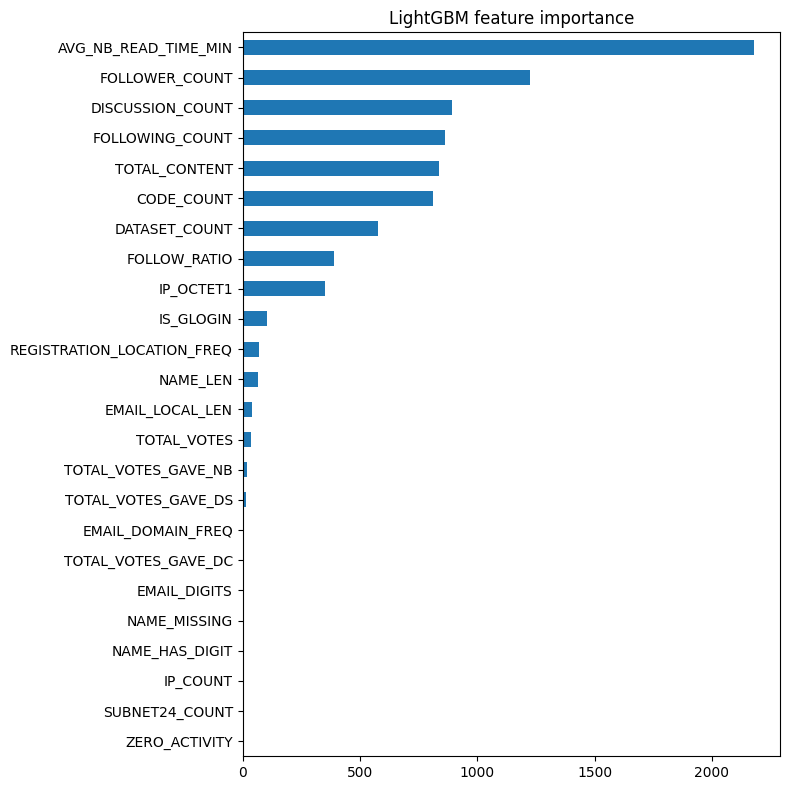

In [53]:
import matplotlib.pyplot as plt
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, average_precision_score)

def evaluate(name, model, X, y):
    proba = model.predict_proba(X)[:, 1]
    pred = (proba >= 0.5).astype(int)
    print(f"=== {name} ===")
    print(classification_report(y, pred, digits=4))
    print("Confusion matrix:\n", confusion_matrix(y, pred))
    print("ROC-AUC:", roc_auc_score(y, proba))
    print("PR-AUC :", average_precision_score(y, proba))
    print("Baseline PR-AUC (positive rate):", y.mean())
    print()

evaluate("Logistic Regression", logreg, X_test_imp, y_test)
evaluate("LightGBM", lgbm, X_test, y_test)

# feature importance (LightGBM)
importance = pd.Series(lgbm.feature_importances_, index=X_train.columns).sort_values()
importance.plot(kind="barh", figsize=(8, 8), title="LightGBM feature importance")
plt.tight_layout()
plt.show()

## Interpretation

c:\Users\admin\anaconda3\envs\multiagent-env\lib\site-packages\shap\explainers\_tree.py:586: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


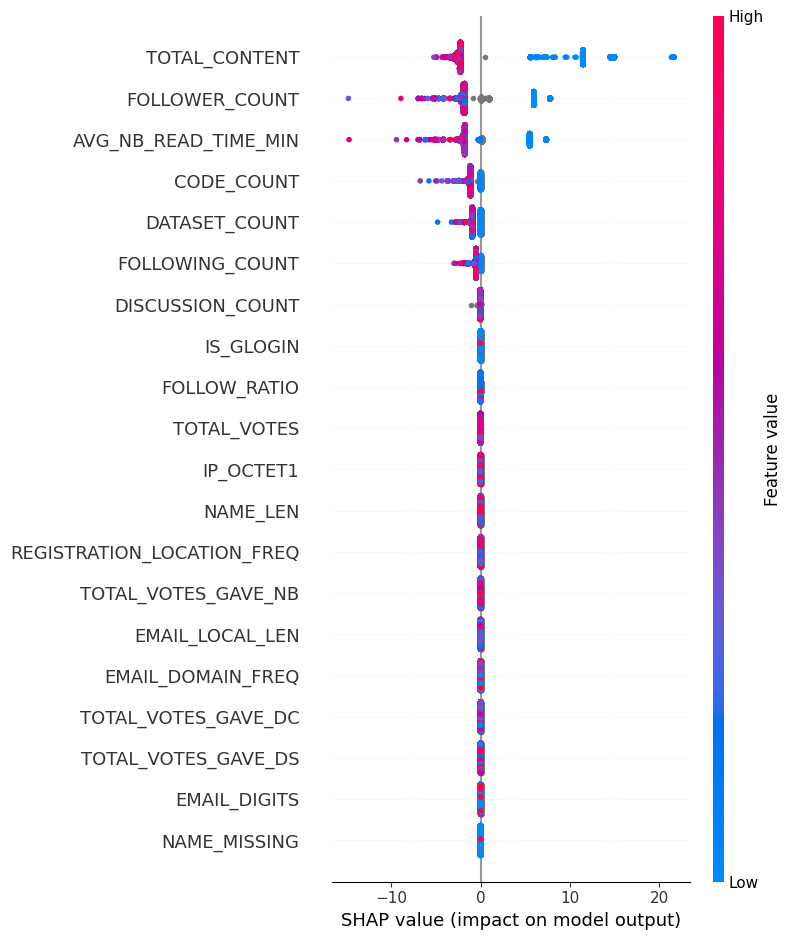

In [54]:
import shap

sample = X_test.sample(10000, random_state=42)
explainer = shap.TreeExplainer(lgbm)
shap_values = explainer.shap_values(sample)
if isinstance(shap_values, list):  # older shap versions return one array per class
    shap_values = shap_values[1]
shap.summary_plot(shap_values, sample)

### More SHAP plots

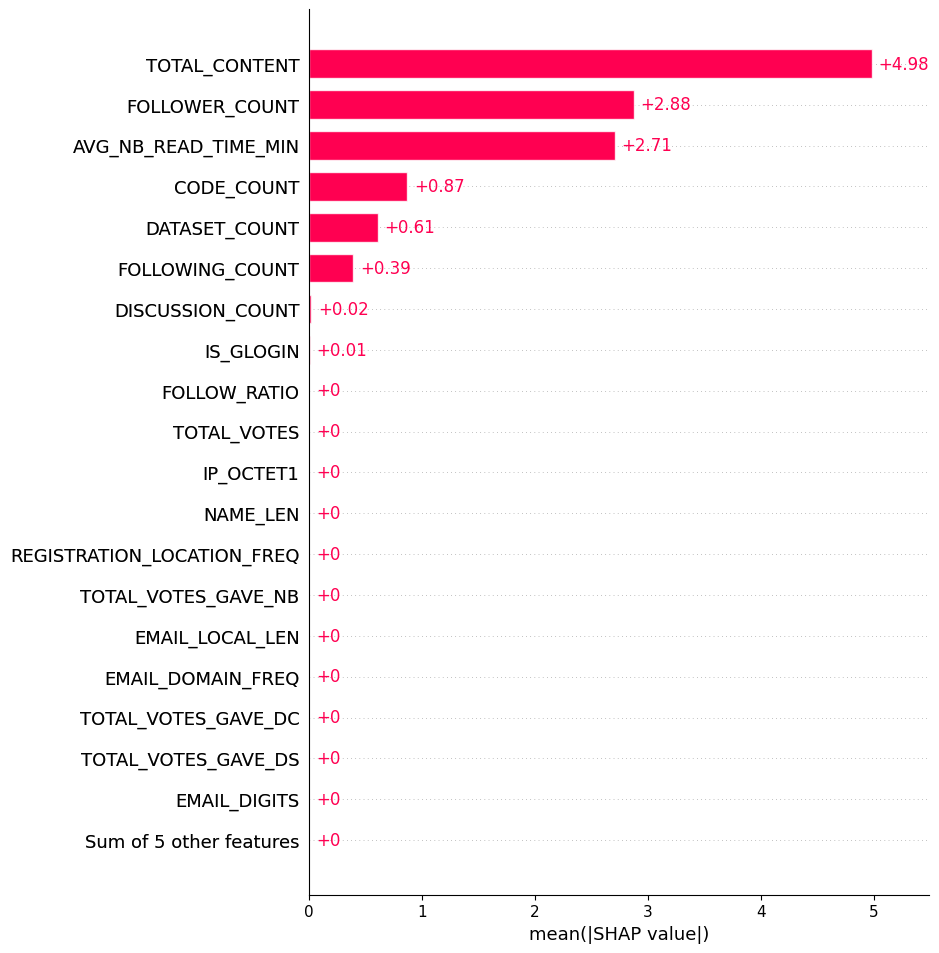

In [46]:
# Build an Explanation object for the newer shap.plots.* API
exp = explainer(sample)
if exp.values.ndim == 3:  # some versions return one slice per class
    exp = exp[:, :, 1]

shap.plots.bar(exp, max_display=20)

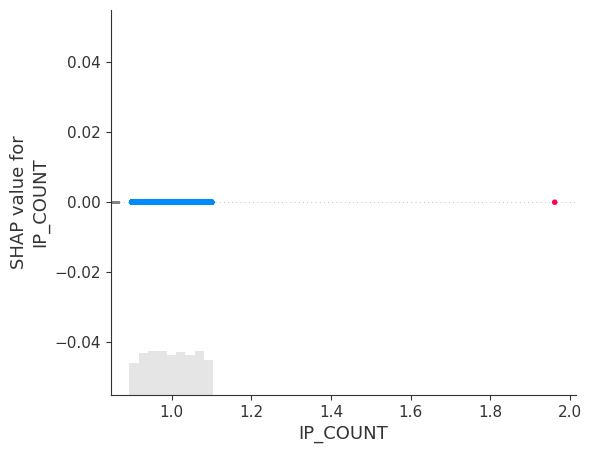

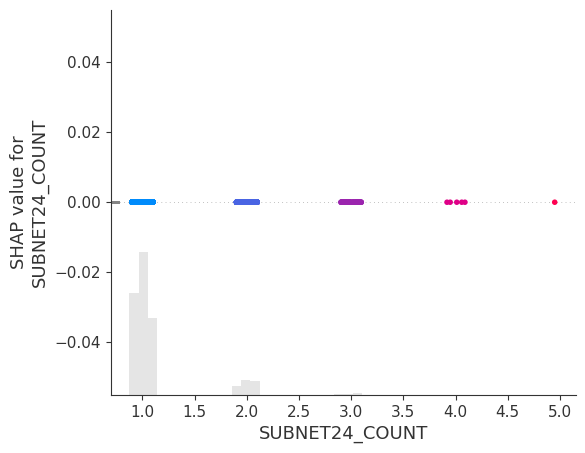

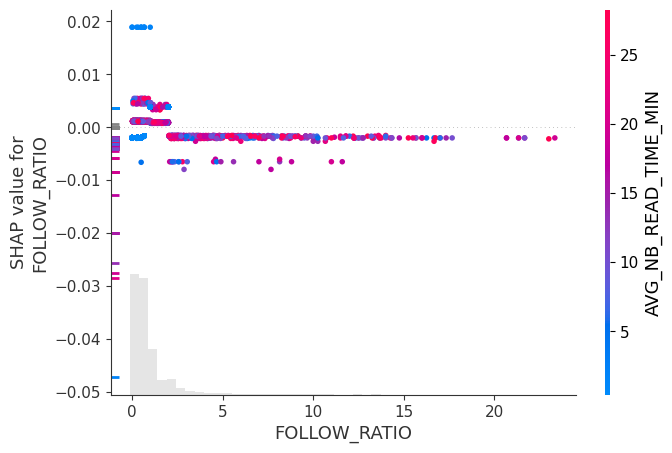

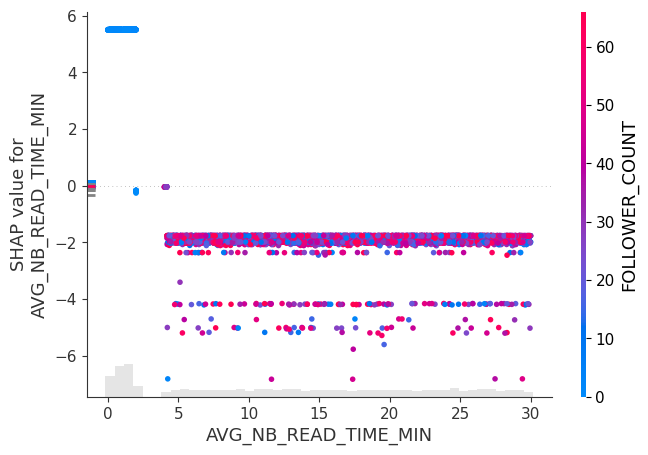

In [47]:
# Dependence plots: how a feature's value moves the prediction
for feat in ["IP_COUNT", "SUBNET24_COUNT", "FOLLOW_RATIO", "AVG_NB_READ_TIME_MIN"]:
    if feat in sample.columns:
        shap.plots.scatter(exp[:, feat], color=exp)

Most confident bot   (p=1.000)


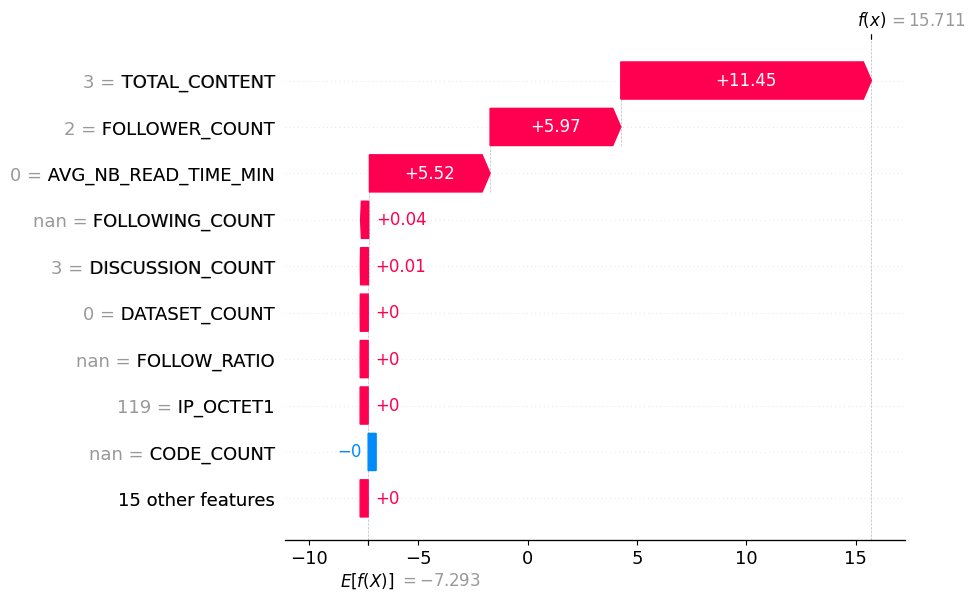

Most confident human (p=0.000)


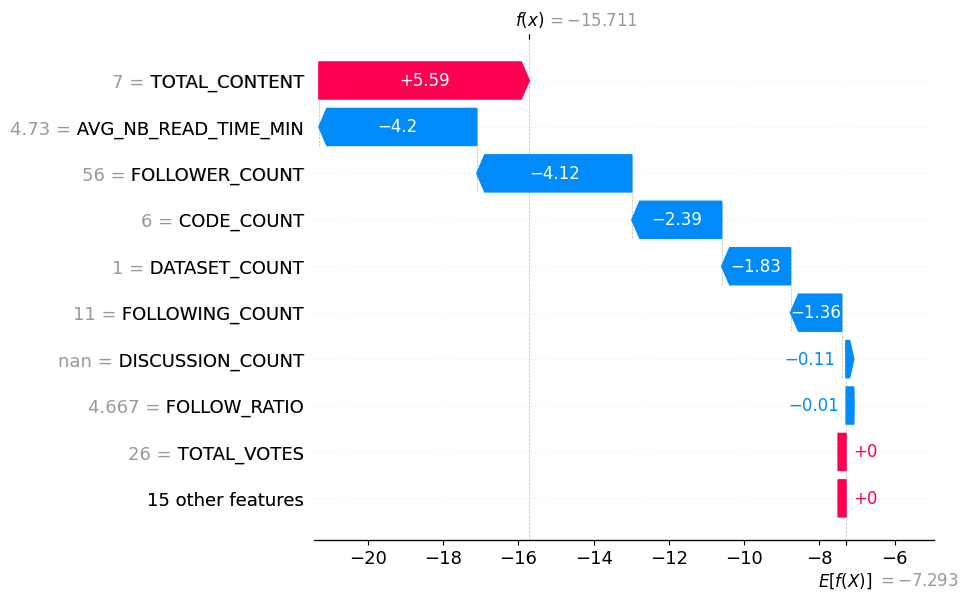

In [48]:
# Waterfall: why the model flagged the most confident bot / most confident human
proba = lgbm.predict_proba(sample)[:, 1]
most_bot = int(proba.argmax())
most_human = int(proba.argmin())

print(f"Most confident bot   (p={proba[most_bot]:.3f})")
shap.plots.waterfall(exp[most_bot])

print(f"Most confident human (p={proba[most_human]:.3f})")
shap.plots.waterfall(exp[most_human])

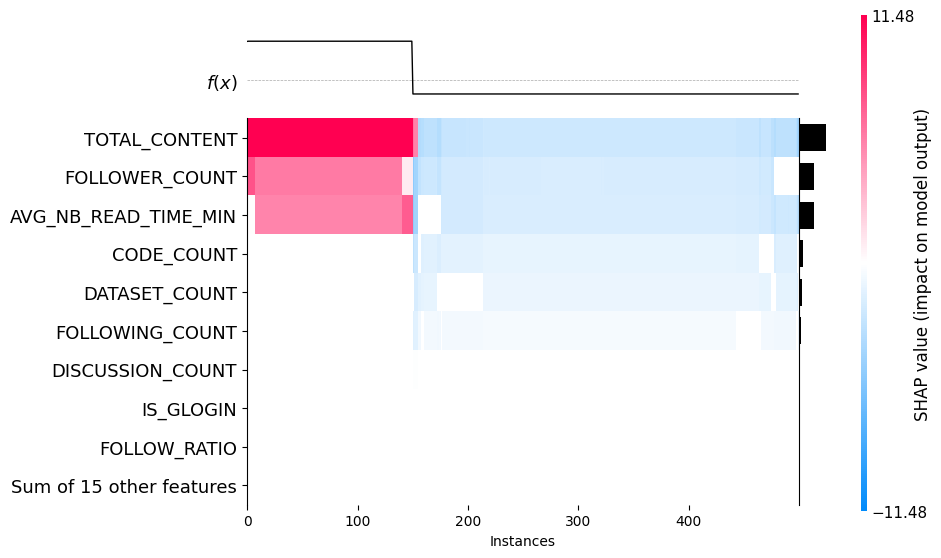

<Axes: xlabel='Instances'>

In [49]:
# Heatmap: SHAP values for 500 accounts, ordered by similarity
shap.plots.heatmap(exp[:500])